# Day 6 roadmap

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_16.png" alt="Heatmap" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Heatmaps — <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">sns.heatmap()</span></h3>
			<p>Display numerical values using colors. Learn
				<span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">annot</span>, <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">cmap</span>, and <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">linewidths</span>.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_17.png" alt="Correlation heatmap" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Correlation heatmaps</h3>
			<p>Explore relationships between numerical
				columns using Pandas <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">.corr().</span></p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_18.png" alt="Clustered heatmap" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Clustered heatmaps — <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">sns.clustermap()</span></h3>
			<p>Learn how similar rows and columns can be
				grouped together.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_19.png" alt="Mini project" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Mini project</h3>
			<p>Build a correlation heatmap using the
				familiar <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">tips</span> dataset.</p>
		</td>
	</tr>
</table>

# Lesson 1 — Understanding a heatmap
A **heatmap** represents numerical values using colors. Depending on the color map, larger values may appear darker or brighter than smaller values.

For example, imagine this table of average scores:
| Student | Python | Maths | DBMS |
| :--- | :--- | :--- | :--- |
| A | 85 | 70 | 90 |
| B | 60 | 80 | 65 |
| C | 95 | 88 | 92 |

A heatmap can help us identify high and low values quickly without reading every number.

Explanation: `sns.heatmap()`
The basic syntax is:
```python
sns.heatmap(data)
```
Some useful parameters:
| Parameter | Purpose |
| :--- | :--- |
| annot=True | Displays values inside cells |
| cmap="coolwarm" | Sets the color map |
| linewidths=0.5 | Adds spacing between cells |
| fmt=".2f" | Formats annotations to two decimal places |
| cbar=True | Displays the color scale |

## Create your first heatmap
### Imports and Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

scores = pd.DataFrame({
    "Python": [85, 60, 95],
    "Math": [70, 80, 88],
    "DBMS": [90, 65, 92]
}, index=["Student A", "Student B", "Student C"])

scores

,Python,Math,DBMS
Student A,85,70,90
Student B,60,80,65
Student C,95,88,92


### Heatmap

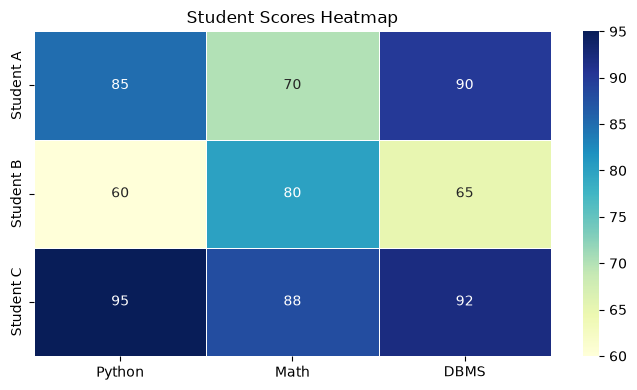

In [3]:
plt.figure(figsize=(7, 4))

sns.heatmap(
    scores,
    annot=True,
    cmap="YlGnBu",
    lw=0.5,
    fmt="d"
)

plt.title("Student Scores Heatmap")

plt.tight_layout()

plt.show()

# Lesson 2 — Correlation heatmaps
Now let's apply heatmaps to your familiar `tips` dataset. We'll calculate correlations between numerical columns such as `total_bill`, `tip`, and `size`, then visualize them.

Before running the code, one important concept: correlation ranges from -1 to +1.
- `+1`: perfect positive linear relationship.
- `0`: no linear correlation.
- `-1`: perfect negative linear relationship.

## Explanation: What is a correlation matrix?
A **correlation matrix** is a table that shows how strongly numerical variables are linearly related to one another.

For our `tips` dataset, we'll examine:
- `total_bill` — the total restaurant bill
- `tip` — the tip amount
- `size` — the number of people at the table
The correlation coefficient ranges from -1 to +1.

| Correlation | Meaning |
| :--- | :--- |
| Close to `+1` | Strong positive linear relationship |
| Close to `0` | Weak or no linear relationship |
| Close to `-1` | Strong negative linear relationship |

Remember: **correlation does not prove causation.**

## Calculate the correlation matrix

In [4]:
# Load the tips dataset
df = sns.load_dataset("tips")

# Select numerical columns
numeric_df = df[["total_bill", "tip", "size"]]

# Calculate correlations
corr = numeric_df.corr()

corr

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


**What does `.corr()` do?**
`numeric_df.corr()` calculates the pairwise Pearson correlation coefficients by default.

You'll get a matrix with values from `-1` to `+1`. Each variable's correlation with itself is `1.0`, so the diagonal will contain ones.

## Visualize the matrix with a heatmap

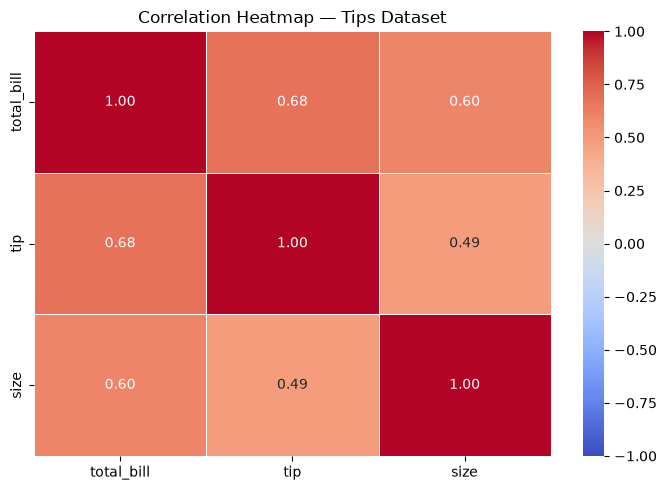

In [5]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    lw=0.5,
    fmt=".2f"
)

plt.title("Correlation Heatmap — Tips Dataset")

plt.tight_layout()

plt.show()

**Understand the parameters**
- `annot=True`: displays correlation values in the cells.
- `cmap="coolwarm"`: uses contrasting cool and warm colors.
- `vmin=-1`, `vmax=1`: fixes the color scale to the full correlation range.
- `center=0`: centers the color scale at zero.
- `fmt=".2f"`: displays values to two decimal places.

**Let's interpret your heatmap**\
focus on these three things:
1. `total_bill` vs `tip`: A positive correlation means larger bills tend to be associated with larger tips.
2. `total_bill` vs `size`: Check whether larger tables tend to have larger bills.
3. `tip` vs `size`: Check how tip amounts are associated with the number of people at a table.

Remember that a correlation measures the strength and direction of a linear relationship. It doesn't prove causation.

**Understanding your correlation matrix**
| Variable pair | Correlation | Interpretation |
| :--- | :--- | :--- |
| `total_bill` ↔ `tip` | **+0.676** | Moderately strong positive relationship |
| `total_bill` ↔ `size` | **+0.598** | Moderate positive relationship |
| `tip` ↔ `size` | **+0.489** | Moderate positive relationship |
| Each variable with itself | **1.000** | Perfect positive correlation |

**What do these values tell us?**
- **Total bill and tip:** Larger bills tend to be associated with larger tips. This is the strongest relationship among the three pairs.
- **Total bill and table size:** Larger groups tend to have larger bills.
- **Tip and table size:** Larger groups tend to leave larger tips, although this relationship is weaker than the other two.

Remember, correlation measures association, not causation. These values also don't tell us whether customers tip a higher percentage of their bill.

# Lesson 3 — Clustered heatmaps
Now let's learn `sns.clustermap()`. Unlike a regular heatmap, it **groups similar rows and columns together** using hierarchical clustering.

**Explanation**
- `sns.heatmap()` displays values in a grid.
- `sns.clustermap()` displays a heatmap with dendrograms that show how rows and columns are grouped by similarity.
- Clustering is useful for discovering patterns in larger datasets.

***Impoortant Notice***\
Seaborn needs **SciPy** to run `sns.clustermap()`, so before running the code we need to install Scipy

In [6]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [7]:
import scipy
import seaborn as sns
import matplotlib.pyplot as plt

print(scipy.__version__)
print(sns.__version__)

1.18.1
0.13.2


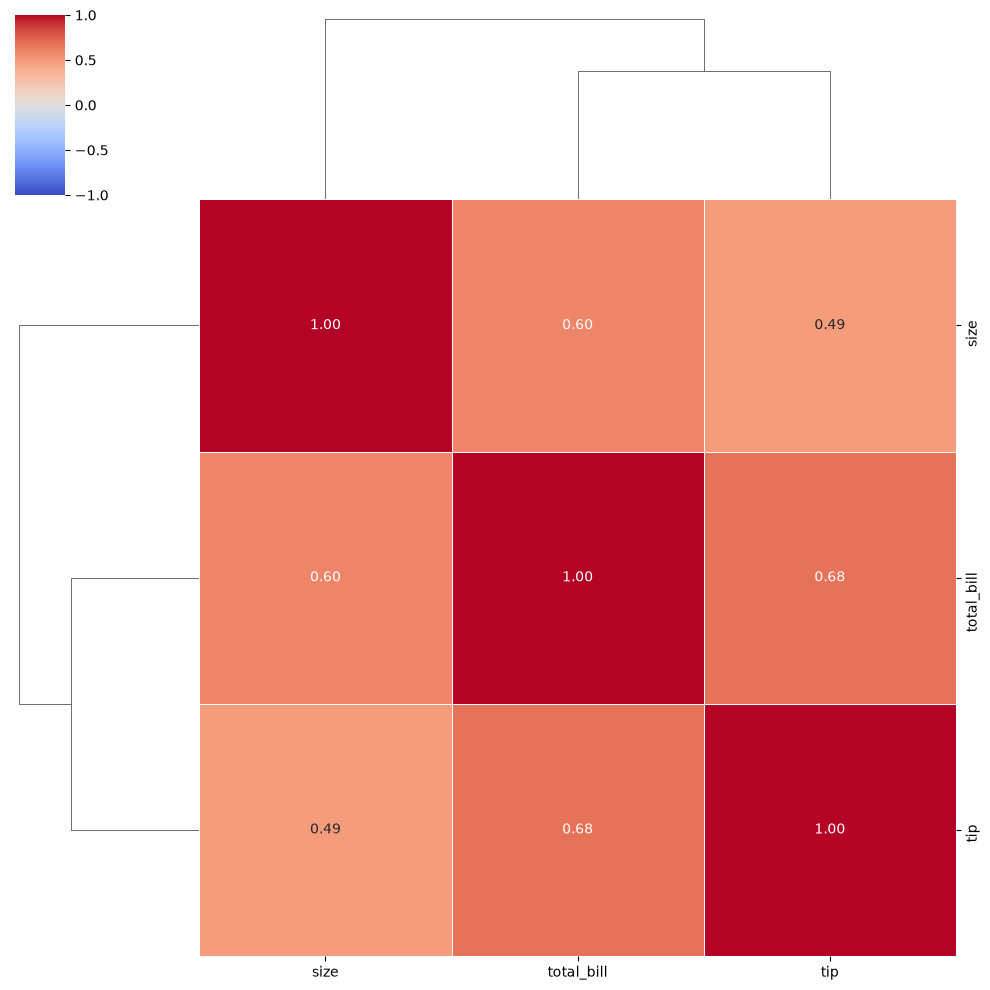

In [8]:
sns.clustermap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    fmt=".2f"
)

plt.show()

## Predict before running

In [26]:

from IPython.display import HTML, display

display(HTML("""
<div style="font-family:Arial,sans-serif; max-width:750px; line-height:1.6;">
    <h2><h2>

    <form id="clusterQuiz">
        <p><b>Q1. What do dendrograms show?</b></p>
        <label><input type="radio" name="q1" value="a">
        A. Exact correlation values</label><br>
        <label><input type="radio" name="q1" value="b">
        B. How rows and columns are grouped by similarity</label><br>
        <label><input type="radio" name="q1" value="c">
        C. The number of missing values</label><br><br>

        <p><b>Q2. Does clustering change the underlying correlation values?</b></p>
        <label><input type="radio" name="q2" value="a">
        A. Yes, it recalculates them differently</label><br>
        <label><input type="radio" name="q2" value="b">
        B. No, it reorders rows and columns to show similarity</label><br><br>

        <p><b>Q3. Which function is suited to discovering groups of similar variables?</b></p>
        <label><input type="radio" name="q3" value="a">
        A. sns.clustermap()</label><br>
        <label><input type="radio" name="q3" value="b">
        B. sns.countplot()</label><br>
        <label><input type="radio" name="q3" value="c">
        C. sns.histplot()</label>

        <br><br>
        <button type="button" onclick="
            let answers = {q1:'b', q2:'b', q3:'a'};
            let score = 0;
            let output = '';
            for (let q in answers) {
                let selected = document.querySelector(
                    '#clusterQuiz input[name='+q+']:checked'
                );
                if (!selected) {
                    output += q.toUpperCase() + ': Not answered<br>';
                } else if (selected.value === answers[q]) {
                    score++;
                    output += q.toUpperCase() + ': Correct<br>';
                } else {
                    output += q.toUpperCase() + ': Incorrect<br>';
                }
            }
            document.getElementById('clusterResult').innerHTML =
                '<b>Score: ' + score + '/3</b><br>' + output;
        ">Check Answers</button>

        <p id="clusterResult"></p>
    </form>
</div>
"""))

# Day 6 — Final Quiz

In [10]:

from IPython.display import HTML, display

display(HTML("""
<div style="font-family:Arial,sans-serif; max-width:750px; line-height:1.6;">
    <h2></h2>

    <form id="finalQuiz">
        <p><b>Q1. Which parameter displays numerical values inside heatmap cells?</b></p>
        <label><input type="radio" name="q1" value="a">
        A. cmap=True</label><br>
        <label><input type="radio" name="q1" value="b">
        B. annot=True</label><br>
        <label><input type="radio" name="q1" value="c">
        C. fmt=True</label>

        <p><b>Q2. What does a correlation of -0.90 suggest?</b></p>
        <label><input type="radio" name="q2" value="a">
        A. Strong negative linear relationship</label><br>
        <label><input type="radio" name="q2" value="b">
        B. Strong positive linear relationship</label><br>
        <label><input type="radio" name="q2" value="c">
        C. No linear relationship</label>

        <p><b>Q3. Why does sns.clustermap() need SciPy?</b></p>
        <label><input type="radio" name="q3" value="a">
        A. To load the tips dataset</label><br>
        <label><input type="radio" name="q3" value="b">
        B. To draw ordinary bar charts</label><br>
        <label><input type="radio" name="q3" value="c">
        C. To perform hierarchical clustering</label>

        <br><br>
        <button type="button" onclick="
            let answers = {q1:'b', q2:'a', q3:'c'};
            let score = 0;
            let output = '';
            for (let q in answers) {
                let selected = document.querySelector(
                    '#finalQuiz input[name='+q+']:checked'
                );
                if (!selected) {
                    output += q.toUpperCase() + ': Not answered<br>';
                } else if (selected.value === answers[q]) {
                    score++;
                    output += q.toUpperCase() + ': Correct<br>';
                } else {
                    output += q.toUpperCase() + ': Incorrect<br>';
                }
            }
            document.getElementById('finalResult').innerHTML =
                '<b>Score: ' + score + '/3</b><br>' + output;
        ">Check Answers</button>

        <p id="finalResult"></p>
    </form>
</div>
"""))

# Day 6 Mini-Project: Matrix Visualization Dashboard
**Goal:** Use Seaborn's `tips` dataset to build three visualizations:
1. A correlation heatmap.
2. A clustered correlation heatmap.
3. A pivot-table heatmap comparing average tips across days and meal times.

## Load and inspect the data

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

print(df.shape)
df.head()

(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Visualization 1: Correlation heatmap

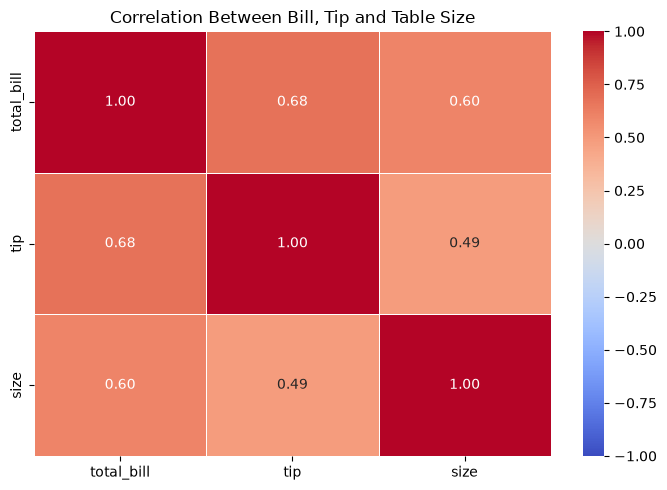

In [12]:
numeric_df = df[["total_bill", "tip", "size"]]
corr = numeric_df.corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Correlation Between Bill, Tip and Table Size")
plt.tight_layout()
plt.show()

## Visualization 2: Clustered heatmap

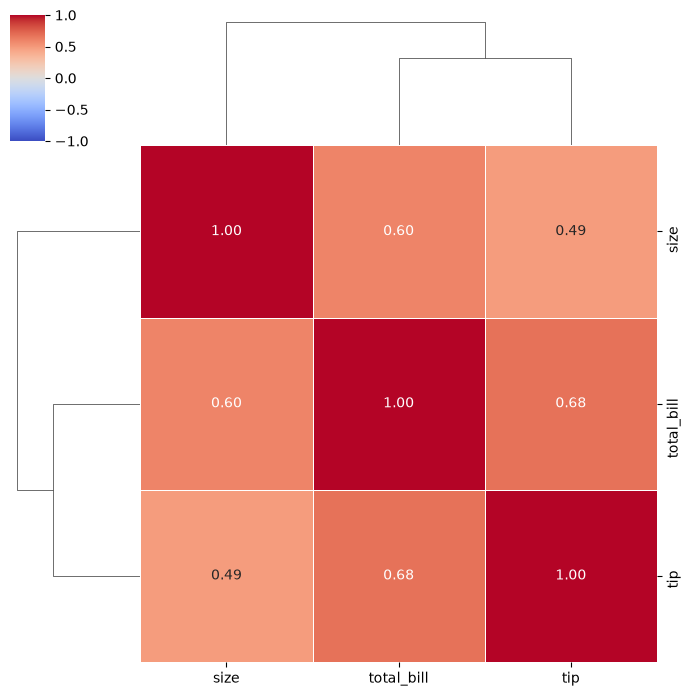

In [13]:
sns.clustermap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    fmt=".2f",
    figsize=(7, 7)
)

plt.show()

## Visualization 3: Average tip by day and meal time
First, create a pivot table.

In [14]:
tip_pivot = df.pivot_table(
    index="day",
    columns="time",
    values="tip",
    aggfunc="mean",
    observed=False
)

tip_pivot

time,Lunch,Dinner
day,,
Thur,2.767705,3.000000
Fri,2.382857,2.940000
Sat,NaN,2.993103
Sun,NaN,3.255132


The rows represent days, the columns represent Lunch and Dinner, and each cell contains the average tip for that combination.

The dataset doesn't contain any Lunch observations for Saturday or Sunday. Therefore, Pandas cannot calculate an average tip for those combinations, so it returns `NaN` (Not a Number).

**Important:** `NaN` here does not mean that the tip amount was zero. It means there are no observations available for that combination.

Now plot it:

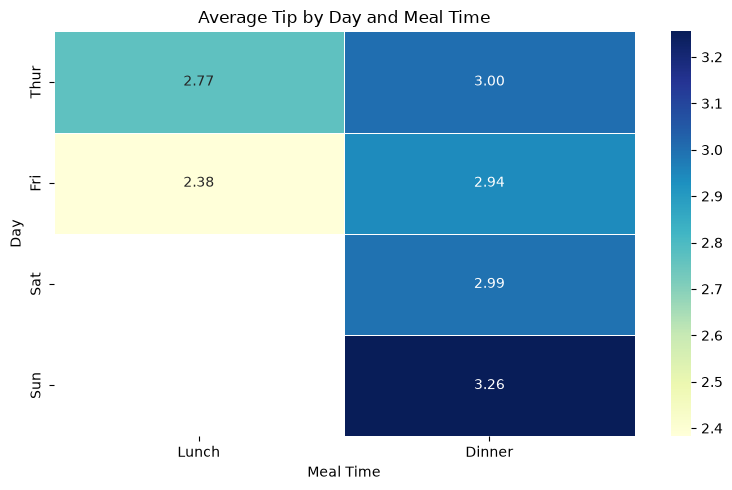

In [15]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    tip_pivot,
    annot=True,
    cmap="YlGnBu",
    linewidths=0.5,
    fmt=".2f"
)

plt.title("Average Tip by Day and Meal Time")
plt.xlabel("Meal Time")
plt.ylabel("Day")
plt.tight_layout()
plt.show()

**Interpretation:** Compare the colors and values to identify which day-and-meal combinations have higher or lower average tips. Some combinations may be missing from the dataset, so their cells can appear blank.

## Combine the visualizations into a dashboard
This final figure places the two heatmaps together, while the clustered heatmap remains a separate figure because `sns.clustermap()` creates its own figure.

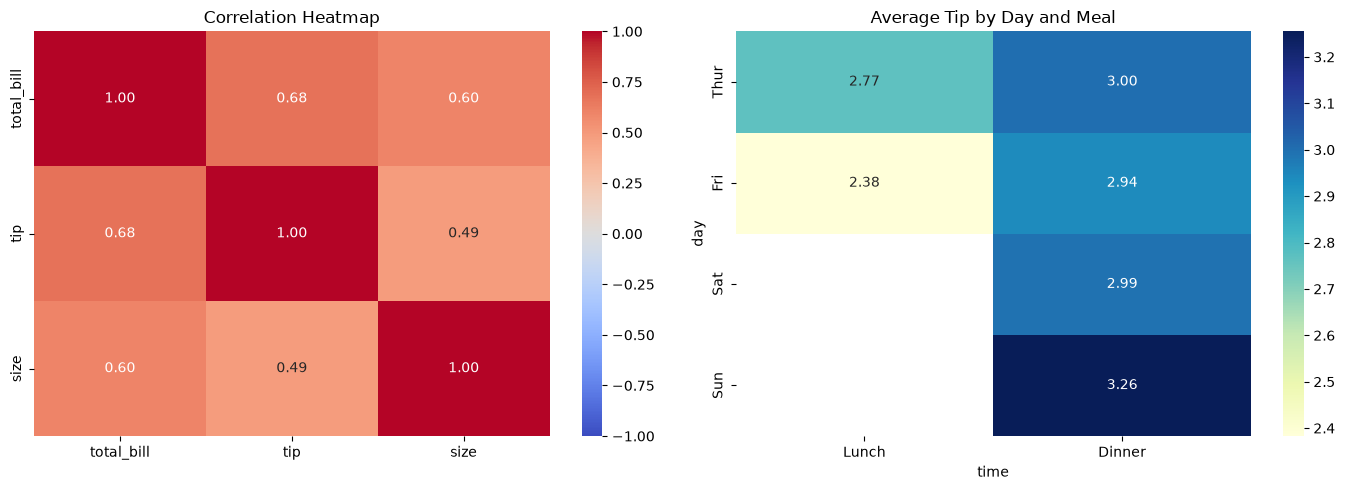

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    ax=axes[0]
)
axes[0].set_title("Correlation Heatmap")

sns.heatmap(
    tip_pivot,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("Average Tip by Day and Meal")

plt.tight_layout()
plt.show()

# Seaborn Day 6 — Practice Challenge

In [17]:

from IPython.display import HTML, display

display(HTML("""
<div id="seaborn-day6-quiz" style="font-family: Arial, sans-serif; line-height: 1.6;">
    <h3></h3>
    <p>Test your understanding of heatmaps, correlations, and clustered heatmaps.</p>

    <form id="quiz-form">

        <p><b>Q1. Which parameter displays numerical values inside heatmap cells?</b></p>
        <label><input type="radio" name="q1" value="a"> A. cmap=True</label><br>
        <label><input type="radio" name="q1" value="b"> B. annot=True</label><br>
        <label><input type="radio" name="q1" value="c"> C. fmt=True</label><br>

        <p><b>Q2. A correlation coefficient of -0.90 indicates:</b></p>
        <label><input type="radio" name="q2" value="a"> A. A strong negative linear relationship</label><br>
        <label><input type="radio" name="q2" value="b"> B. A strong positive linear relationship</label><br>
        <label><input type="radio" name="q2" value="c"> C. No linear relationship</label><br>

        <p><b>Q3. Why does sns.clustermap() require SciPy?</b></p>
        <label><input type="radio" name="q3" value="a"> A. To load CSV files</label><br>
        <label><input type="radio" name="q3" value="b"> B. To create Matplotlib titles</label><br>
        <label><input type="radio" name="q3" value="c"> C. To perform hierarchical clustering</label><br>

        <p><b>Q4. What does aggfunc="mean" calculate in a pivot table?</b></p>
        <label><input type="radio" name="q4" value="a"> A. The average value for each group</label><br>
        <label><input type="radio" name="q4" value="b"> B. The maximum value for each group</label><br>
        <label><input type="radio" name="q4" value="c"> C. The number of missing values</label><br>

        <p><b>Q5. What does NaN mean in your day-and-meal heatmap?</b></p>
        <label><input type="radio" name="q5" value="a"> A. The average tip is zero</label><br>
        <label><input type="radio" name="q5" value="b"> B. The data is invalid and must be deleted</label><br>
        <label><input type="radio" name="q5" value="c"> C. There are no observations for that combination</label><br>

        <br>
        <button type="button" onclick="
            const form = document.getElementById('quiz-form');
            const answers = {q1:'b', q2:'a', q3:'c', q4:'a', q5:'c'};
            let score = 0;
            let unanswered = 0;

            for (const q in answers) {
                const selected = form.querySelector('input[name=' + q + ']:checked');
                if (!selected) {
                    unanswered++;
                } else if (selected.value === answers[q]) {
                    score++;
                }
            }

            const result = document.getElementById('quiz-result');
            if (unanswered > 0) {
                result.innerHTML = 'Please answer all 5 questions before submitting.';
                result.style.color = '#b45309';
            } else {
                result.innerHTML = 'Your score: ' + score + '/5 ' +
                    (score === 5 ? '🎉 Excellent work!' :
                    score >= 3 ? '👍 Good effort! Review the missed concepts.' :
                    '📚 Review Day 6 and try again.');
                result.style.color = score >= 3 ? '#15803d' : '#b91c1c';
            }
        " style="padding: 9px 18px; cursor: pointer;">
            Submit Answers
        </button>

        <p id="quiz-result" style="font-weight: bold; margin-top: 15px;"></p>
    </form>
</div>
"""))
